/Users/jtakalai/python/propaganda-radar/regression/.venv/lib/python3.13/site-packages/sklearn/feature_extraction/text.py:412: UserWarning: Your stop_words may be inconsistent with your preprocessing. Tokenizing the stop words generated tokens ['bb', 'br', 'dir', 'gl', 'gosp', 'inž', 'itd', 'mn', 'npr', 'ruk', 'sc', 'sl', 'str', 'sv', 'tj', 'tzv', 'ul'] not in stop_words.
  warnings.warn(


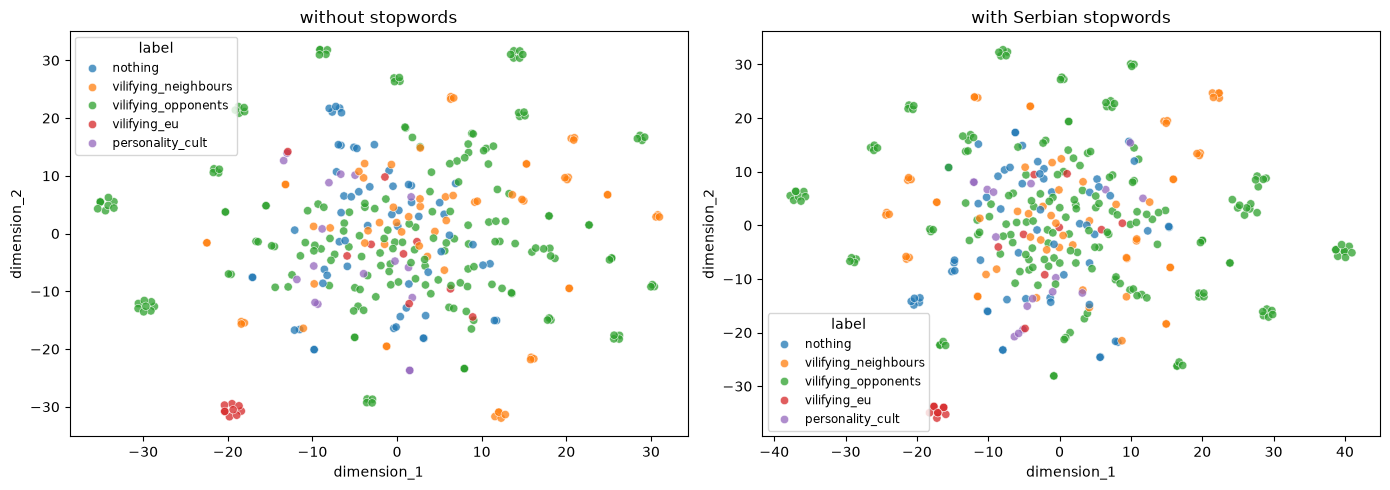

In [3]:
from pathlib import Path
import sys

import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns
from sklearn.manifold import TSNE
from sklearn.decomposition import TruncatedSVD

sys.path.insert(0, str(Path.cwd()))

from data import load_data, load_stopwords
from model import build_model

data = load_data()
stopword_options = {
    "without stopwords": None,
    "with Serbian stopwords": load_stopwords(),
}

perplexity = min(20, max(5, (len(data) - 1) // 3))
fig, axes = plt.subplots(1, len(stopword_options), figsize=(14, 5))

for axis, (name, stopwords) in zip(axes, stopword_options.items()):
    model = build_model(stopwords)
    features = model.named_steps["tfidf"].fit_transform(data["headline"])
    n_components = min(50, features.shape[1] - 1, features.shape[0] - 1)
    reduced = TruncatedSVD(n_components=n_components, random_state=42).fit_transform(features)
    embedding = TSNE(
        n_components=2,
        perplexity=perplexity,
        init="random",
        random_state=42,
    ).fit_transform(reduced)

    plot_data = pd.DataFrame(embedding, columns=["dimension_1", "dimension_2"])
    plot_data["label"] = data["label"].to_numpy()
    sns.scatterplot(
        data=plot_data,
        x="dimension_1",
        y="dimension_2",
        hue="label",
        ax=axis,
        alpha=0.75,
    )
    axis.set_title(name)
    axis.legend(title="label", fontsize="small")

plt.tight_layout()
plt.show()

In [ ]:
# t-SNE visualization

TF-IDF vectors are reduced with TruncatedSVD before t-SNE because the original matrix is sparse and high-dimensional. The plot is exploratory: visible separation is not a measure of classifier quality.